# 01 — Exploring the diffsky mock with OpenCosmo

The input of `romanmock` is Andrew Hearin's diffsky lightcone. This notebook shows how the
catalog is organised, what the emission-line columns contain, and how to turn the stored line
luminosities (erg/s) into observed fluxes (erg/s/cm²) with `romanmock.add_line_fluxes`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

## Slices of the lightcone

The mock is split into thin redshift shells, one file per HACC step. `romanmock.io` reads the
headers only (cheap) to list them.

In [2]:
from romanmock.io import list_catalog_files, file_info, open_catalog, load_aux_data

files = list_catalog_files(CATALOG)
print(f"{len(files)} slices")
infos = [file_info(f) for f in files]
for info in infos[::6]:
    print(f"step {info.step:4d}  z = [{info.z_min:.3f}, {info.z_max:.3f}]  n = {info.n_gal:>12,}")
print("total galaxies:", f"{sum(i.n_gal for i in infos):,}")

67 slices


step   97  z = [3.855, 4.000]  n =    3,453,453
step  113  z = [3.205, 3.313]  n =    4,695,187
step  131  z = [2.655, 2.736]  n =    6,128,365
step  151  z = [2.170, 2.252]  n =    8,643,519
step  176  z = [1.738, 1.799]  n =    7,739,086
step  203  z = [1.376, 1.433]  n =    8,223,424
step  235  z = [1.055, 1.107]  n =    7,270,235
step  272  z = [0.779, 0.824]  n =    5,421,039
step  315  z = [0.539, 0.578]  n =    3,229,551
step  365  z = [0.335, 0.364]  n =    1,298,500
step  421  z = [0.154, 0.184]  n =      426,979
step  487  z = [0.000, 0.024]  n =        3,378
total galaxies: 324,137,133


## Opening a slice

`open_catalog` wraps `opencosmo.open` with the flags diffsky's own loader uses. The result is an
`opencosmo.Lightcone`; nothing is read from disk until `get_data` is called.

In [3]:
cat = open_catalog([f for f in files if f.name.startswith("lc_cores-219.")])
print(cat.z_range, len(cat), "galaxies")
print(cat.cosmology)

(1.208791208791209, 1.2584269662921352) 7112654 galaxies
FlatLambdaCDM(H0=67.66 km / (Mpc s), Om0=0.3096446816186967, Tcmb0=0.0 K, Neff=3.04, m_nu=None, Ob0=0.04897468161869667)


In [4]:
line_cols = ["Ba_alpha_6563", "Ba_beta_4861", "O_III_4363", "O_III_4959", "O_III_5007",
             "O_II_3726", "O_II_3729", "S_III_6312", "S_III_9069", "S_III_9532"]
for c in line_cols + ["redshift_obs", "redshift_true", "vpec", "av"]:
    print(f"{c:<16s} {str(cat.units[c]):<10s} {cat.descriptions[c]}")

Ba_alpha_6563    erg / s    Emission line luminosity (continuum-subtracted)
Ba_beta_4861     erg / s    Emission line luminosity (continuum-subtracted)
O_III_4363       erg / s    Emission line luminosity (continuum-subtracted)
O_III_4959       erg / s    Emission line luminosity (continuum-subtracted)
O_III_5007       erg / s    Emission line luminosity (continuum-subtracted)
O_II_3726        erg / s    Emission line luminosity (continuum-subtracted)
O_II_3729        erg / s    Emission line luminosity (continuum-subtracted)
S_III_6312       erg / s    Emission line luminosity (continuum-subtracted)
S_III_9069       erg / s    Emission line luminosity (continuum-subtracted)
S_III_9532       erg / s    Emission line luminosity (continuum-subtracted)
redshift_obs     None       Observed redshift, accounting for line-of-sight peculiar velocity
redshift_true    None       True redshift
vpec             km / s     Peculiar line-of-sight velocity in physical km/s
av               None      

The diffsky auxiliary files carry the SSP metadata, including the vacuum rest wavelength of each
line. `romanmock` uses these wavelengths (its built-in table is identical).

In [5]:
aux = load_aux_data(CATALOG)
wave = aux["ssp_data"].ssp_emline_wave
for name, w in zip(wave._fields, wave):
    print(f"{name:<14s} {w:9.3f} A")

Ba_alpha_6563   6564.723 A
Ba_beta_4861    4862.763 A
O_III_4363      4364.294 A
O_III_4959      4960.370 A
O_III_5007      5008.314 A
O_II_3726       3727.118 A
O_II_3729       3730.119 A
S_III_6312      6313.902 A
S_III_9069      9071.246 A
S_III_9532      9533.378 A


## Line luminosities

Read a contiguous block of 300k galaxies. The luminosities include dust attenuation and are
continuum subtracted.

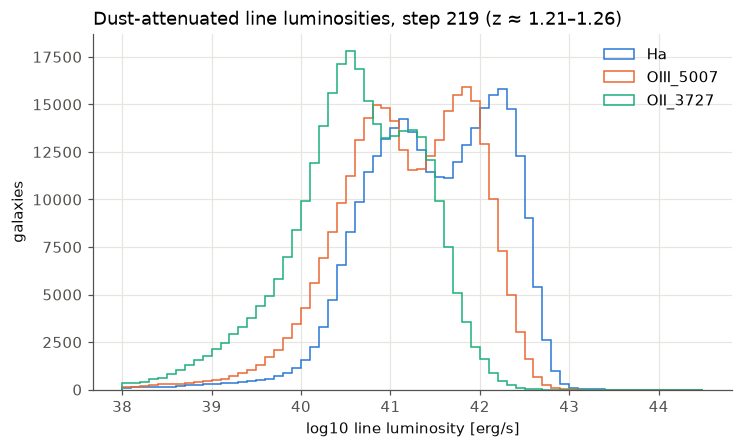

In [6]:
sub = cat.take(300_000, at="start")
lum = sub.select(*line_cols, "redshift_obs", "logsm_obs").get_data("numpy", wrap_single=True)

fig, ax = plt.subplots()
series = [("Ha", lum["Ba_alpha_6563"]), ("OIII_5007", lum["O_III_5007"]), ("OII_3727", lum["O_II_3726"] + lum["O_II_3729"])]
bins = np.linspace(38, 44.5, 66)
for name, L in series:
    ax.hist(np.log10(L), bins=bins, histtype="step", color=plotting.feature_color(name), label=name)
ax.set_xlabel("log10 line luminosity [erg/s]"); ax.set_ylabel("galaxies")
ax.set_title(f"Dust-attenuated line luminosities, step 219 (z ≈ {cat.z_range[0]:.2f}–{cat.z_range[1]:.2f})")
ax.legend(); plt.show()

## From luminosity to flux

`add_line_fluxes` sums the components of each feature (for example the [O II] doublet), converts
with `F = L / (4π D_L²)` using the cosmology of the file header, and returns a dataset with one
`<feature>_flux` column per feature, in erg/s/cm². The luminosity distance is evaluated at the
cosmological redshift (`redshift_true`).

In [7]:
from romanmock import add_line_fluxes, get_line_set

line_set = get_line_set("roman_transitions")
print(line_set.describe())
with_flux = add_line_fluxes(sub, line_set)
flux = with_flux.select(*[f"{f.name}_flux" for f in line_set]).get_data("numpy", wrap_single=True)
print(with_flux.units["Ha_flux"], "|", with_flux.descriptions["OII_3727_flux"])

LineSet 'roman_transitions': bit -> feature (rest wavelength [A]; components)
  bit  0 (value          1): Ha          6564.723  Ba_alpha_6563  H-alpha 6563
  bit  1 (value          2): Hb          4862.763  Ba_beta_4861  H-beta 4861
  bit  2 (value          4): OIII_5007   5008.314  O_III_5007  [O III] 5007
  bit  3 (value          8): OIII_4959   4960.370  O_III_4959  [O III] 4959
  bit  4 (value         16): OII_3727    3728.619  O_II_3726+O_II_3729  [O II] 3726+3729 blend
  bit  5 (value         32): SIII_9532   9533.378  S_III_9532  [S III] 9532
  bit  6 (value         64): SIII_9069   9071.246  S_III_9069  [S III] 9069
  bit  7 (value        128): OIII_4363   4364.294  O_III_4363  [O III] 4363 (auroral)
  bit  8 (value        256): SIII_6312   6313.902  S_III_6312  [S III] 6312 (auroral)


erg / (s cm2) | Observed line flux of [O II] 3726+3729 blend (sum of O_II_3726+O_II_3729), dust attenuation included


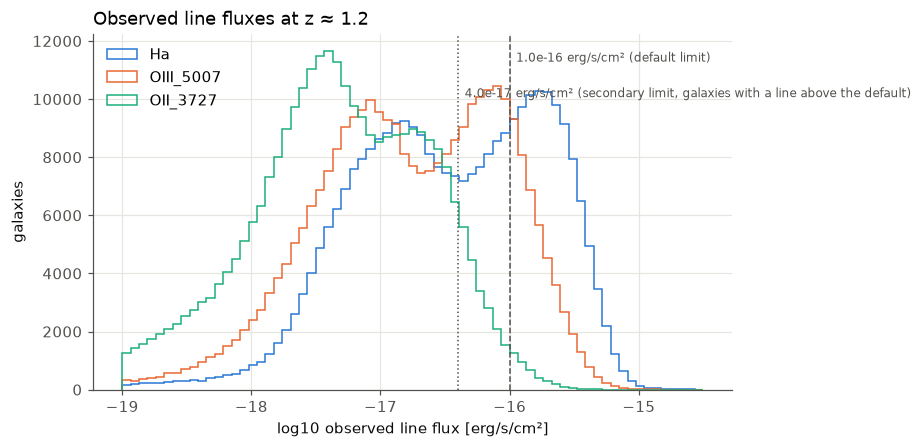

In [8]:
from romanmock.roman import DEFAULT_LINE_FLUX_LIMIT, DEFAULT_SECONDARY_LINE_FLUX_LIMIT

fig, ax = plt.subplots()
bins = np.linspace(-19, -14.5, 70)
for name in ["Ha", "OIII_5007", "OII_3727"]:
    ax.hist(np.log10(flux[f"{name}_flux"]), bins=bins, histtype="step", color=plotting.feature_color(name), label=name)
ymax = ax.get_ylim()[1]
for lim, ls, y, text in [(DEFAULT_LINE_FLUX_LIMIT, "--", 0.95, "default limit"),
                         (DEFAULT_SECONDARY_LINE_FLUX_LIMIT, ":", 0.85, "secondary limit, galaxies with a line above the default")]:
    ax.axvline(np.log10(lim), color=plotting.TEXT_SECONDARY, lw=1, ls=ls)
    ax.text(np.log10(lim) + 0.05, ymax * y, f"{lim:.1e} erg/s/cm² ({text})", color=plotting.TEXT_SECONDARY, fontsize=8, va="top")
ax.set_xlabel("log10 observed line flux [erg/s/cm²]"); ax.set_ylabel("galaxies")
ax.set_title("Observed line fluxes at z ≈ 1.2"); ax.legend(); plt.show()

## Which lines fall in the Roman grism?

The grism covers 1.00–1.93 μm. Plotting `λ_obs = λ₀ (1 + z)` for every feature shows which
redshift ranges each line is observable in, and where two lines can be confused
(for example [O III] 5007 at z ≈ 2.2 and Hα at z ≈ 1.44 both land at 1.6 μm).

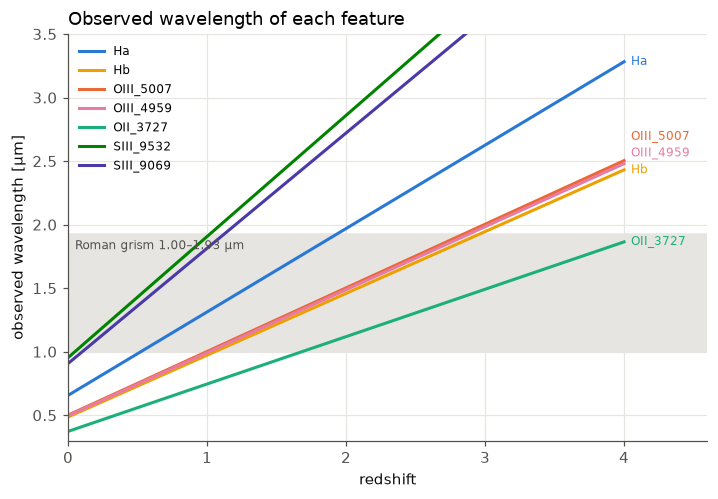

In [9]:
from romanmock.roman import GRISM_WAVE_RANGE_ANGSTROM

z = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.axhspan(*[w / 1e4 for w in GRISM_WAVE_RANGE_ANGSTROM], color=plotting.GRID, zorder=0)
ax.text(0.05, GRISM_WAVE_RANGE_ANGSTROM[1] / 1e4 - 0.05, "Roman grism 1.00–1.93 μm", color=plotting.TEXT_SECONDARY, fontsize=8, va="top")
ymax = 3.5
labels = []
for feat in line_set:
    if feat.name in ("OIII_4363", "SIII_6312"):
        continue
    lam = feat.rest_wave * (1 + z) / 1e4
    ax.plot(z, lam, color=plotting.feature_color(feat.name), label=feat.name)
    if lam[-1] <= ymax:                       # direct labels only where the line reaches the right edge
        labels.append([z[-1] + 0.05, lam[-1], feat.name])
labels.sort(key=lambda l: l[1])               # nudge labels apart vertically
for k in range(1, len(labels)):
    if labels[k][0] > 4 and labels[k - 1][0] > 4 and labels[k][1] - labels[k - 1][1] < 0.13:
        labels[k][1] = labels[k - 1][1] + 0.13
for x, y, name in labels:
    ax.text(x, min(y, ymax - 0.05), name, color=plotting.feature_color(name), fontsize=8, va="center")
ax.set_xlim(0, 4.6); ax.set_ylim(0.3, ymax)
ax.set_xlabel("redshift"); ax.set_ylabel("observed wavelength [μm]")
ax.set_title("Observed wavelength of each feature"); ax.legend(loc="upper left", fontsize=8); plt.show()